# Session 27 Solutions: Probability and Simulation

Data Science with Python, Level 2, Stage 4: Statistics

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(27)
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"

## In-Class Exercises

### In-Class Exercise 1: Two Dice

In [2]:
total = rng.integers(1, 7, 100_000) + rng.integers(1, 7, 100_000)
print(round((total == 7).mean(), 4), round(6 / 36, 4))

0.1664 0.1667


### In-Class Exercise 2: Exam Guessing

In [3]:
print(round(1 - stats.binom.cdf(4, 10, 0.25), 4))

0.0781


### In-Class Exercise 3: Fraud Rate

In [4]:
tx = pd.read_csv(DATA_URL + "card_transactions.csv")
print(round(tx["is_fraud"].mean(), 4))
print(tx.groupby("online")["is_fraud"].mean().round(4))
print(tx.groupby("new_merchant")["is_fraud"].mean().round(4))

0.018
online
False    0.0057
True     0.0399
Name: is_fraud, dtype: float64
new_merchant
False    0.0056
True     0.0790
Name: is_fraud, dtype: float64


### In-Class Exercise 4: Sample Means

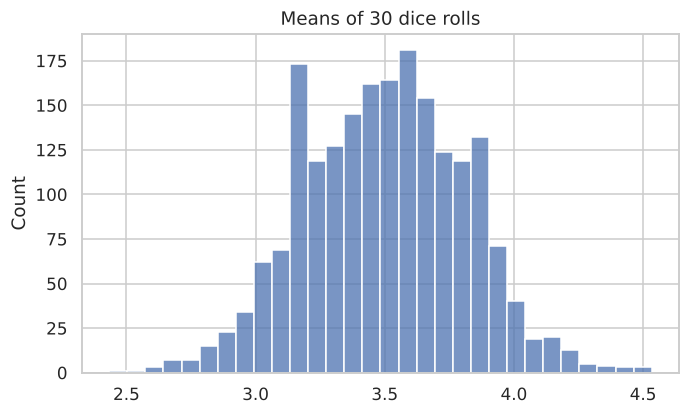

In [5]:
means = rng.integers(1, 7, size=(2000, 30)).mean(axis=1)
sns.histplot(means, bins=30)
plt.title("Means of 30 dice rolls")
plt.show()

## Part A: Basic

### Exercise 1: Coin Experiments

In [6]:
for n in [10, 100, 100_000]:
    print(n, (rng.integers(0, 2, n)).mean())
# The share wanders for small numbers of flips and settles near 0.5 for many flips: the law of large numbers.

10 0.4
100 0.46
100000 0.5015


### Exercise 2: Probability Rules

In [7]:
exact_none = (5 / 6) ** 6
games = rng.integers(1, 7, size=(100_000, 6))
sim_none = (~(games == 6).any(axis=1)).mean()
print(round(exact_none, 4), round(sim_none, 4))
print(round(1 - exact_none, 4), round(1 - sim_none, 4))

0.3349 0.3328
0.6651 0.6672


## Part B: Intermediate

### Exercise 3: Waiting for a Six

In [8]:
waits = []
for _ in range(50_000):
    n = 1
    while rng.integers(1, 7) != 6:
        n += 1
    waits.append(n)
waits = np.array(waits)
print(round(waits.mean(), 2), round((waits > 10).mean(), 3))

5.98 0.16


### Exercise 4: Churn by Two Factors

In [9]:
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
churn["left"] = churn["churn"] == "Yes"
pt = pd.pivot_table(churn, index="contract", columns="internet", values="left", aggfunc="mean").round(3)
print(pt)
print("Overall:", round(churn["left"].mean(), 3))

internet          DSL  Fiber
contract                    
Month-to-month  0.382  0.563
One year        0.143  0.206
Two year        0.044  0.115
Overall: 0.303


## Part C: Challenge

### Exercise 5: A Queue Simulation

When customers arrive almost as fast as they are served, queues grow quickly. Simulation shows this without any queueing formula.

In [10]:
def simulate(mean_gap, customers=200):
    arrival, free_at, waits = 0.0, 0.0, []
    for _ in range(customers):
        arrival += rng.exponential(mean_gap)
        start = max(arrival, free_at)
        waits.append(start - arrival)
        free_at = start + rng.uniform(2, 4)
    return np.array(waits)

for gap in [3.0, 2.5]:
    w = simulate(gap)
    print(gap, round(w.mean(), 2), round((w > 5).mean(), 3))

3.0 26.38 0.805
2.5 51.21 0.935


## Part D: Cumulative Project: Exam Scores Study

### Exercise 6: Exam Scores Study: Part 2

In [11]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
print("P(passed):", round(exams["passed"].mean(), 3))
print("P(passed | study > 10):", round(exams.loc[exams["study_hours_week"] > 10, "passed"].mean(), 3))
print("P(math > 70 | sleep >= 8):", round((exams.loc[exams["sleep_hours"] >= 8, "math"] > 70).mean(), 3))
print("P(math > 70 | sleep < 6):", round((exams.loc[exams["sleep_hours"] < 6, "math"] > 70).mean(), 3))
passed = exams["passed"].to_numpy()
classes = rng.choice(passed, size=(10_000, 30))
print("P(fewer than 10 of 30 pass):", round((classes.sum(axis=1) < 10).mean(), 3))

P(passed): 0.45
P(passed | study > 10): 0.838
P(math > 70 | sleep >= 8): 0.234
P(math > 70 | sleep < 6): 0.103
P(fewer than 10 of 30 pass): 0.069


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Complement rule: 1 - 0.3. |
| 2 | B | For independent events, multiply: 0.5 x 0.2. |
| 3 | B | Independent flips have no memory. |
| 4 | B | Averages over many trials settle near the true value. |
| 5 | B | It is the share who left among monthly customers. |